# Processing multiple spectra

This notebook is for users who already understand a single O25 correction. It reads several spectra and geometries from one CSV file, constructs one reusable `O25Model`, and processes observations with a straightforward loop.

The loop is intentionally explicit. It is easier to inspect and adapt than a highly optimized multidimensional interface.


In [2]:
from pathlib import Path
import csv
import sys

import matplotlib.pyplot as plt
import numpy as np


# Locate the downloaded O25 repository automatically.
here = Path.cwd().resolve()

candidates = [here, *here.parents]

# Also support Jupyter starting one directory above the repository.
candidates.extend(
    folder / "O25"
    for folder in [here, *here.parents]
)

repository = next(
    (
        folder
        for folder in candidates
        if (folder / "o25" / "__init__.py").is_file()
        and (folder / "examples" / "data").is_dir()
    ),
    None,
)

if repository is None:
    raise RuntimeError(
        "The O25 repository could not be located automatically. "
        "Keep this notebook inside the downloaded O25 repository."
    )

# Make the local package available to this notebook.
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))

import o25


# First 12 OLCI wavelengths used by BH4.
wl = np.array(
    [
        400, 412, 443, 490, 510, 560,
        620, 665, 673, 681, 709, 753,
    ],
    dtype=float,
)

data_file = (
    repository
    / "examples"
    / "data"
    / "spectra_batch.csv"
)

with open(data_file, newline="", encoding="utf-8") as file:
    rows = list(csv.DictReader(file))

# The same loaded model can be reused for all observations.
model = o25.O25Model()

print("O25 is ready.")
print("Batch file loaded:", data_file.name)
print("Number of spectra:", len(rows))

O25 is ready.
Batch file loaded: spectra_batch.csv
Number of spectra: 3


## Run every observation

Each row contains one spectrum and one source geometry. The target defaults to `(0, 0, 0)`.


In [3]:
results = []
for row in rows:
    spectrum = np.array([float(row[f"Rrs_{int(x)}"]) for x in wl])
    g0 = (float(row["solar_zenith_deg"]),
          float(row["viewing_zenith_deg"]),
          float(row["relative_azimuth_deg"]))
    result = model.correct(wl, spectrum, g0)
    results.append((row["spectrum_id"], spectrum, g0, result))
    print(row["spectrum_id"], "class=", result.k, "status=", result.uncertainty_status)


A class= 4 status= available_native_olci
B class= 4 status= available_native_olci
C class= 4 status= available_native_olci


## Corrected spectra and uncertainty

The figure compares all O25-corrected spectra. The vertical error bars show BH4 dimensional uncertainty in the same units as corrected Rrs.

Each legend entry reports:

the spectrum identifier;
the source geometry g0;
the assigned BH4 class.

All observations use the probability shown in the figure title. The error-bar size is calculated as:

u = u_rel × |Rrs corrected|

The error bars are empirical BH4 uncertainty bounds and should not automatically be interpreted as one standard deviation.

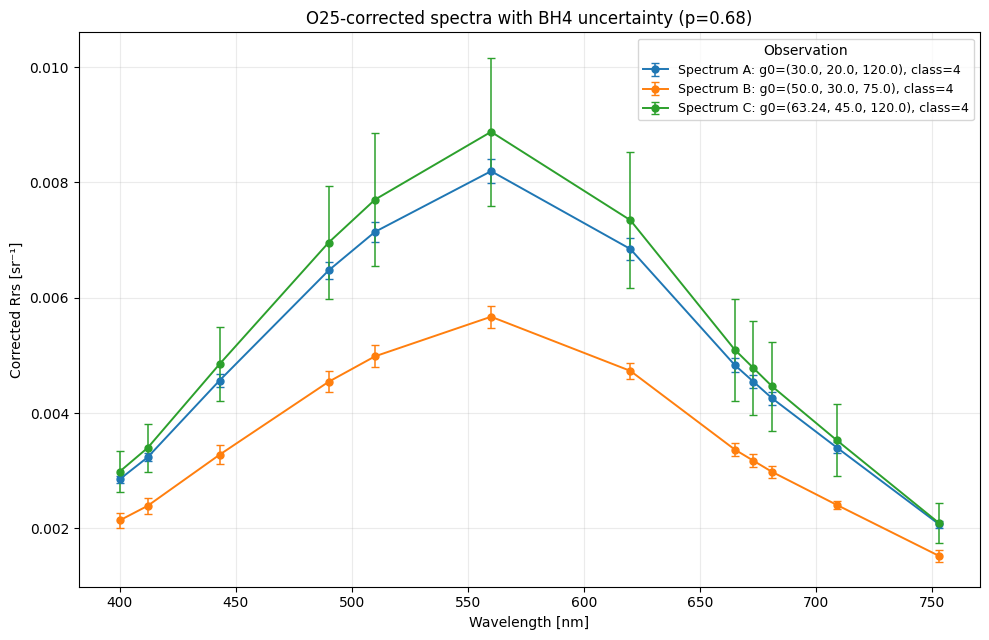

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.5))

for sid, spectrum, g0, r in results:
    ax.errorbar(
        wl,
        r.Rrs,
        yerr=r.u,
        fmt="o-",
        linewidth=1.4,
        markersize=5,
        elinewidth=1.1,
        capsize=3,
        label=(
            f"Spectrum {sid}: "
            f"g0={g0}, class={r.k}"
        ),
    )

ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel("Corrected Rrs [sr⁻¹]")
ax.set_title(
    f"O25-corrected spectra with BH4 uncertainty "
    f"(p={results[0][3].p:g})"
)

ax.grid(True, alpha=0.25)
ax.legend(
    title="Observation",
    fontsize=9,
)
fig.tight_layout()

plt.show()

## Inspect one result with uncertainty bars

For one selected spectrum, the vertical bars again use dimensional uncertainty in Rrs units.


## Save a compact batch summary

For simplicity, this summary stores one row per spectrum with class and status. Full spectral outputs can be stored in separate long-format files if needed.


In [ ]:
summary_file = data_file.with_name("batch_summary.csv")
with open(summary_file, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["spectrum_id", "bh4_class", "probability", "uncertainty_status"])
    for sid, spectrum, g0, r in results:
        writer.writerow([sid, r.k, r.p, r.uncertainty_status])
print("Saved:", summary_file)
